In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import math
import os
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
import torchvision
from torchvision import transforms
from torchvision.models import resnet18

os.makedirs("artifacts", exist_ok=True)
MEAN = (0.5071, 0.4867, 0.4408)
STD = (0.2675, 0.2565, 0.2761)


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def get_transforms(train=True):
    if not train:
        return transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    return transforms.Compose([
        transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])


class CIFAR100Split(Dataset):
    def __init__(self, images, labels, indices, class_names, transform=None):
        self.images = images[indices]
        self.labels = labels[indices].astype(np.int64)
        self.global_indices = indices
        self.class_names = class_names
        self.transform = transform
        self._to_pil = transforms.ToPILImage()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self._to_pil(self.images[idx])
        label = int(self.labels[idx])
        tensor = self.transform(img) if self.transform is not None else transforms.ToTensor()(img)
        return tensor, label, idx

    def get_raw_image(self, idx):
        return self.images[idx]


def split_indices(labels, seed=42):
    rng = np.random.RandomState(seed)
    train_idx, val_idx, test_idx = [], [], []
    for c in range(100):
        perm = rng.permutation(np.where(labels == c)[0])
        train_idx.append(perm[:480])
        val_idx.append(perm[480:540])
        test_idx.append(perm[540:600])
    return {
        "train": np.concatenate(train_idx),
        "val": np.concatenate(val_idx),
        "test": np.concatenate(test_idx),
    }


class PKBatchSampler(Sampler):
    def __init__(self, labels, p_classes=32, k_samples=4, seed=42):
        self.labels = np.asarray(labels)
        self.p_classes = p_classes
        self.k_samples = k_samples
        self.batch_size = p_classes * k_samples
        self.seed = seed
        self.epoch = 0
        self.classes = np.unique(self.labels)
        self.class_map = {int(c): np.where(self.labels == c)[0] for c in self.classes}
        self.num_batches = len(self.labels) // self.batch_size

    def __iter__(self):
        rng = np.random.RandomState(self.seed + self.epoch)
        self.epoch += 1
        pools = {c: rng.permutation(idxs).tolist() for c, idxs in self.class_map.items()}
        for _ in range(self.num_batches):
            chosen = rng.choice(self.classes, size=self.p_classes, replace=False)
            batch = []
            for c in chosen:
                c_int = int(c)
                if len(pools[c_int]) < self.k_samples:
                    pools[c_int] = rng.permutation(self.class_map[c_int]).tolist()
                for _ in range(self.k_samples):
                    batch.append(pools[c_int].pop())
            yield batch

    def __len__(self):
        return self.num_batches


def load_cifar100_splits(data_root="./data", seed=42):
    tr_ds = torchvision.datasets.CIFAR100(root=data_root, train=True, download=True)
    te_ds = torchvision.datasets.CIFAR100(root=data_root, train=False, download=True)
    images = np.concatenate([tr_ds.data, te_ds.data], axis=0)
    labels = np.concatenate([np.array(tr_ds.targets), np.array(te_ds.targets)], axis=0)
    class_names = list(tr_ds.classes)
    splits = split_indices(labels, seed=seed)
    datasets = {
        "train": CIFAR100Split(images, labels, splits["train"], class_names, get_transforms(True)),
        "val": CIFAR100Split(images, labels, splits["val"], class_names, get_transforms(False)),
        "test": CIFAR100Split(images, labels, splits["test"], class_names, get_transforms(False)),
    }
    return datasets, class_names


class ResNet18Embedder(nn.Module):
    def __init__(self, embedding_dim=128):
        super().__init__()
        backbone = resnet18(weights=None)
        backbone.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        backbone.maxpool = nn.Identity()
        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4
        self.avgpool = backbone.avgpool
        self.fc = nn.Linear(512, embedding_dim)
        nn.init.orthogonal_(self.fc.weight)
        nn.init.zeros_(self.fc.bias)

    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        x = torch.flatten(self.avgpool(x), 1)
        x = self.fc(x)
        return F.normalize(x, p=2, dim=1, eps=1e-12)


class SGD:
    def __init__(self, params, lr=0.05, momentum=0.9, weight_decay=5e-4):
        self.params = [p for p in params if p.requires_grad]
        self.lr = float(lr)
        self.momentum = float(momentum)
        self.weight_decay = float(weight_decay)
        self.velocity = [torch.zeros_like(p.data) for p in self.params]

    def zero_grad(self):
        with torch.no_grad():
            for p in self.params:
                if p.grad is not None:
                    p.grad.zero_()

    def step(self):
        with torch.no_grad():
            for i, p in enumerate(self.params):
                if p.grad is None:
                    continue
                g = p.grad.data + self.weight_decay * p.data
                self.velocity[i].mul_(self.momentum).add_(g)
                p.data.sub_(self.lr * self.velocity[i])


class Adam:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-4):
        self.params = [p for p in params if p.requires_grad]
        self.lr = float(lr)
        self.beta1, self.beta2 = float(betas[0]), float(betas[1])
        self.eps = float(eps)
        self.weight_decay = float(weight_decay)
        self.t = 0
        self.m = [torch.zeros_like(p.data) for p in self.params]
        self.v = [torch.zeros_like(p.data) for p in self.params]

    def zero_grad(self):
        with torch.no_grad():
            for p in self.params:
                if p.grad is not None:
                    p.grad.zero_()

    def step(self):
        self.t += 1
        bc1 = 1.0 - (self.beta1 ** self.t)
        bc2 = 1.0 - (self.beta2 ** self.t)
        with torch.no_grad():
            for i, p in enumerate(self.params):
                if p.grad is None:
                    continue
                g = p.grad.data + self.weight_decay * p.data
                self.m[i].mul_(self.beta1).add_((1.0 - self.beta1) * g)
                self.v[i].mul_(self.beta2).add_((1.0 - self.beta2) * (g * g))
                m_hat = self.m[i] / bc1
                v_hat = self.v[i] / bc2
                p.data.sub_(self.lr * (m_hat / (torch.sqrt(v_hat) + self.eps)))


class NAdam(Adam):
    def step(self):
        self.t += 1
        bc1 = 1.0 - (self.beta1 ** self.t)
        bc2 = 1.0 - (self.beta2 ** self.t)
        with torch.no_grad():
            for i, p in enumerate(self.params):
                if p.grad is None:
                    continue
                g = p.grad.data + self.weight_decay * p.data
                self.m[i].mul_(self.beta1).add_((1.0 - self.beta1) * g)
                self.v[i].mul_(self.beta2).add_((1.0 - self.beta2) * (g * g))
                m_hat = self.m[i] / bc1
                v_hat = self.v[i] / bc2
                m_nest = self.beta1 * m_hat + ((1.0 - self.beta1) / bc1) * g
                p.data.sub_(self.lr * (m_nest / (torch.sqrt(v_hat) + self.eps)))


def pairwise_l2(embeddings, eps=1e-12):
    dot = torch.matmul(embeddings, embeddings.t())
    sq_norm = torch.diag(dot)
    sq_dist = torch.clamp(sq_norm.unsqueeze(1) - 2.0 * dot + sq_norm.unsqueeze(0), min=0.0)
    zero_mask = (sq_dist == 0.0).float()
    return torch.sqrt(sq_dist + zero_mask * eps) * (1.0 - zero_mask)


class TripletLoss(nn.Module):
    def __init__(self, margin=0.3, mining="hard"):
        super().__init__()
        self.margin = float(margin)
        self.mining = mining

    def forward(self, embeddings, labels):
        device = embeddings.device
        b = embeddings.size(0)
        dist_mat = pairwise_l2(embeddings)
        eye = torch.eye(b, dtype=torch.bool, device=device)
        pos_mask = (labels.unsqueeze(1) == labels.unsqueeze(0)) & (~eye)
        neg_mask = labels.unsqueeze(1) != labels.unsqueeze(0)
        valid = (pos_mask.sum(dim=1) > 0) & (neg_mask.sum(dim=1) > 0)

        if valid.sum() == 0:
            return (embeddings * 0.0).sum(), 0.0

        if self.mining == "hard":
            pos_d = dist_mat.clone()
            pos_d[~pos_mask] = -1e9
            d_ap_all, _ = pos_d.max(dim=1)

            sh_mask = neg_mask & (dist_mat > d_ap_all.unsqueeze(1))
            has_sh = sh_mask.any(dim=1)
            neg_sh = dist_mat.clone()
            neg_sh[~sh_mask] = 1e9
            d_an_sh, _ = neg_sh.min(dim=1)

            neg_all = dist_mat.clone()
            neg_all[~neg_mask] = 1e9
            d_an_hard, _ = neg_all.min(dim=1)

            d_ap = d_ap_all[valid]
            d_an = torch.where(has_sh, d_an_sh, d_an_hard)[valid]
        else:
            ap_list, an_list = [], []
            for idx in torch.where(valid)[0]:
                p_idxs = torch.where(pos_mask[idx])[0]
                n_idxs = torch.where(neg_mask[idx])[0]
                ap_list.append(dist_mat[idx, p_idxs[torch.randint(len(p_idxs), (1,), device=device)]])
                an_list.append(dist_mat[idx, n_idxs[torch.randint(len(n_idxs), (1,), device=device)]])
            d_ap = torch.cat(ap_list)
            d_an = torch.cat(an_list)

        losses = torch.clamp(d_ap - d_an + self.margin, min=0.0)
        center_penalty = embeddings.mean(dim=0).pow(2).sum()
        loss = losses.mean() + 0.5 * center_penalty

        with torch.no_grad():
            valid_t = pos_mask.unsqueeze(2) & neg_mask.unsqueeze(1)
            correct_t = (dist_mat.unsqueeze(2) < dist_mat.unsqueeze(1)) & valid_t
            total_t = valid_t.sum().item()
            triplet_acc = float(correct_t.sum().item()) / float(total_t) if total_t > 0 else 0.0

        return loss, triplet_acc


@torch.no_grad()
def evaluate_val_triplet_acc(model, val_loader, margin=0.3, device="cuda"):
    model.eval()
    criterion = TripletLoss(margin=margin, mining="hard")
    accs = []
    for imgs, lbls, _ in val_loader:
        emb = model(imgs.to(device))
        _, acc = criterion(emb, lbls.to(device))
        accs.append(acc)
    return float(np.mean(accs) * 100.0)


def train_part1_model(
    datasets,
    embedding_dim=128,
    margin=0.3,
    mining="hard",
    lr=1e-3,
    batch_size=128,
    epochs=30,
    optimizer_type="adam",
    seed=42,
):
    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    p_classes = batch_size // 4
    train_sampler = PKBatchSampler(datasets["train"].labels, p_classes=p_classes, k_samples=4, seed=seed)
    val_sampler = PKBatchSampler(datasets["val"].labels, p_classes=p_classes, k_samples=4, seed=seed + 10)

    train_loader = DataLoader(datasets["train"], batch_sampler=train_sampler, num_workers=2, pin_memory=True)
    val_loader = DataLoader(datasets["val"], batch_sampler=val_sampler, num_workers=2, pin_memory=True)

    model = ResNet18Embedder(embedding_dim=embedding_dim).to(device)
    if optimizer_type == "sgd":
        optimizer = SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    elif optimizer_type == "nadam":
        optimizer = NAdam(model.parameters(), lr=lr, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-4)
    else:
        optimizer = Adam(model.parameters(), lr=lr, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-4)

    criterion = TripletLoss(margin=margin, mining=mining)
    best_val_acc = 0.0
    best_weights = None

    for epoch in range(epochs):
        t0 = time.time()
        prog = epoch / max(1, epochs - 1)
        optimizer.lr = 1e-5 + (lr - 1e-5) * 0.5 * (1.0 + math.cos(math.pi * prog))
        model.train()
        losses, accs = [], []

        for imgs, lbls, _ in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            emb = model(imgs)
            loss, acc = criterion(emb, lbls)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
            accs.append(acc)

        val_acc = evaluate_val_triplet_acc(model, val_loader, margin=margin, device=device)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if (epoch + 1) % 5 == 0 or epoch == 0 or (epoch + 1) == epochs:
            print(
                f"Epoch {epoch+1:02d}/{epochs:02d} | lr={optimizer.lr:.5f} | "
                f"loss={np.mean(losses):.4f} | train_acc={np.mean(accs)*100:.1f}% | "
                f"val_triplet_acc={val_acc:.2f}% | {time.time()-t0:.1f}s"
            )

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return model, best_val_acc


datasets, class_names = load_cifar100_splits("./data", seed=42)
print("Splits loaded:", {k: len(v) for k, v in datasets.items()})

model, best_val_acc = train_part1_model(
    datasets,
    embedding_dim=128,
    margin=0.3,
    mining="hard",
    lr=1e-3,
    batch_size=128,
    epochs=30,
    optimizer_type="adam",
)
torch.save({"model_state_dict": model.state_dict(), "embedding_dim": 128}, "./artifacts/best_resnet18_triplet.pt")
print(f"Part 1 Complete — Best Validation Triplet Accuracy: {best_val_acc:.2f}%")

100%|██████████| 169M/169M [13:09<00:00, 214kB/s] 


Splits loaded: {'train': 48000, 'val': 6000, 'test': 6000}
Epoch 01/30 | lr=0.00100 | loss=0.3252 | train_acc=60.3% | val_triplet_acc=61.52% | 44.0s
Epoch 05/30 | lr=0.00095 | loss=0.3119 | train_acc=65.6% | val_triplet_acc=66.70% | 45.7s
Epoch 10/30 | lr=0.00078 | loss=0.3002 | train_acc=70.7% | val_triplet_acc=73.15% | 45.6s
Epoch 15/30 | lr=0.00053 | loss=0.2917 | train_acc=76.8% | val_triplet_acc=77.71% | 45.4s
Epoch 20/30 | lr=0.00027 | loss=0.2816 | train_acc=81.6% | val_triplet_acc=82.95% | 45.0s
Epoch 25/30 | lr=0.00008 | loss=0.2732 | train_acc=85.1% | val_triplet_acc=86.56% | 45.2s
Epoch 30/30 | lr=0.00001 | loss=0.2697 | train_acc=86.5% | val_triplet_acc=86.54% | 45.1s
Part 1 Complete — Best Validation Triplet Accuracy: 87.12%


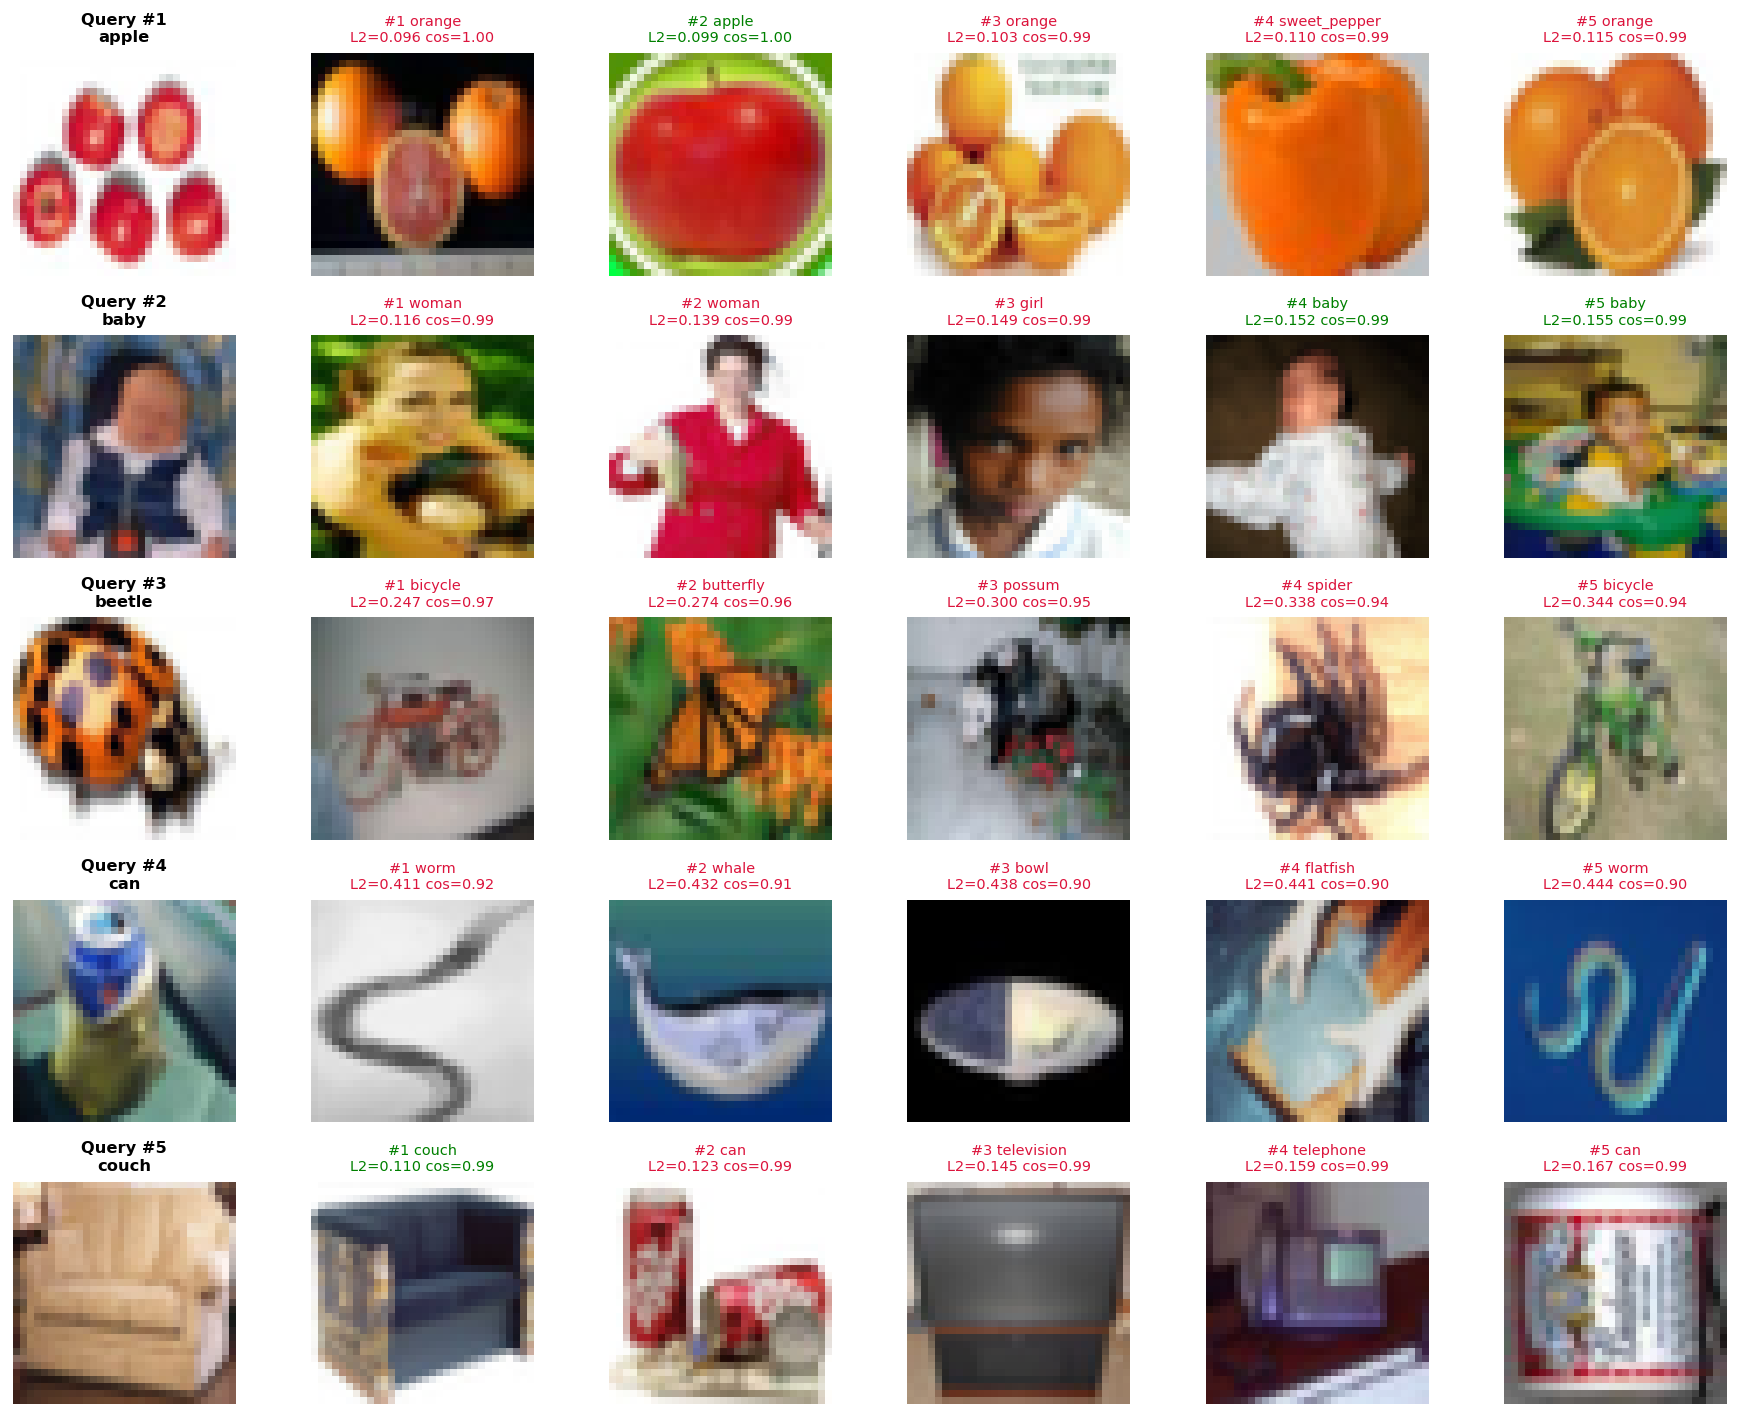

In [2]:
import heapq
import matplotlib.pyplot as plt


@torch.no_grad()
def extract_test_embeddings(model, test_dataset, batch_size=256):
    device = next(model.parameters()).device
    model.eval()
    loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    embs, lbls, idxs = [], [], []
    for imgs, l, i in loader:
        embs.append(model(imgs.to(device)).cpu().numpy().astype(np.float32))
        lbls.append(l.numpy().astype(np.int64))
        idxs.append(i.numpy().astype(np.int64))
    embeddings = np.concatenate(embs, axis=0)
    labels = np.concatenate(lbls, axis=0)
    indices = np.concatenate(idxs, axis=0)
    np.save("./artifacts/test_embeddings.npy", embeddings)
    np.save("./artifacts/test_labels.npy", labels)
    np.save("./artifacts/test_indices.npy", indices)
    return embeddings, labels, indices


def l2_distance_matrix(queries, gallery):
    q_sq = np.sum(queries ** 2, axis=1, keepdims=True)
    g_sq = np.sum(gallery ** 2, axis=1, keepdims=True).T
    return np.sqrt(np.maximum(q_sq - 2.0 * np.dot(queries, gallery.T) + g_sq, 0.0)).astype(np.float32)


def cosine_similarity_matrix(queries, gallery):
    qn = queries / np.maximum(np.linalg.norm(queries, axis=1, keepdims=True), 1e-12)
    gn = gallery / np.maximum(np.linalg.norm(gallery, axis=1, keepdims=True), 1e-12)
    return np.dot(qn, gn.T).astype(np.float32)


class BruteForceRetriever:
    def __init__(self, gallery_embeddings, gallery_labels, class_names):
        self.gallery_embeddings = np.asarray(gallery_embeddings, dtype=np.float32)
        self.gallery_labels = np.asarray(gallery_labels, dtype=np.int64)
        self.class_names = class_names

    def search_l2(self, query_embeddings, top_k=5, exclude_self_indices=None):
        q = np.asarray(query_embeddings, dtype=np.float32)
        if q.ndim == 1:
            q = q[None, :]
        dist_mat = l2_distance_matrix(q, self.gallery_embeddings)
        cos_mat = cosine_similarity_matrix(q, self.gallery_embeddings)
        if exclude_self_indices is not None:
            for r_i, g_i in enumerate(exclude_self_indices):
                if 0 <= g_i < dist_mat.shape[1]:
                    dist_mat[r_i, g_i] = np.inf
        part = np.argpartition(dist_mat, kth=top_k - 1, axis=1)[:, :top_k]
        rows = np.arange(q.shape[0])[:, None]
        order = np.argsort(dist_mat[rows, part], axis=1)
        top_idx = part[rows, order]
        return {
            "indices": top_idx,
            "distances": dist_mat[rows, top_idx],
            "cosine_similarities": cos_mat[rows, top_idx],
            "labels": self.gallery_labels[top_idx],
            "class_names": [[self.class_names[int(c)] for c in row] for row in self.gallery_labels[top_idx]],
        }


test_embeddings, test_labels, test_indices = extract_test_embeddings(model, datasets["test"])
retriever = BruteForceRetriever(test_embeddings, test_labels, class_names)

sample_queries = np.array([0, 120, 450, 980, 1500])
top5_res = retriever.search_l2(test_embeddings[sample_queries], top_k=5, exclude_self_indices=sample_queries)

fig, axes = plt.subplots(5, 6, figsize=(14, 11), dpi=130)
for r_i, q_idx in enumerate(sample_queries):
    q_img = datasets["test"].get_raw_image(int(q_idx))
    q_cls = class_names[int(test_labels[q_idx])]
    axes[r_i, 0].imshow(q_img)
    axes[r_i, 0].set_title(f"Query #{r_i+1}\n{q_cls}", fontsize=9, fontweight="bold")
    axes[r_i, 0].axis("off")

    for c_j in range(5):
        g_idx = int(top5_res["indices"][r_i, c_j])
        g_dist = float(top5_res["distances"][r_i, c_j])
        g_cos = float(top5_res["cosine_similarities"][r_i, c_j])
        g_cls = top5_res["class_names"][r_i][c_j]
        axes[r_i, c_j + 1].imshow(datasets["test"].get_raw_image(g_idx))
        color = "green" if g_cls == q_cls else "crimson"
        axes[r_i, c_j + 1].set_title(f"#{c_j+1} {g_cls}\nL2={g_dist:.3f} cos={g_cos:.2f}", fontsize=8, color=color)
        axes[r_i, c_j + 1].axis("off")

plt.tight_layout()
plt.savefig("./artifacts/top5_retrievals.png", bbox_inches="tight")
plt.show()

Full Test Split Results (lr=1e-3, batch_size=128, margin=0.3, dim=128, hard mining):
Recall@1: 22.78% | Recall@5: 51.65% | Recall@10: 63.83% | mAP: 14.75%


/tmp/ipykernel_49/2730718086.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", num_classes)


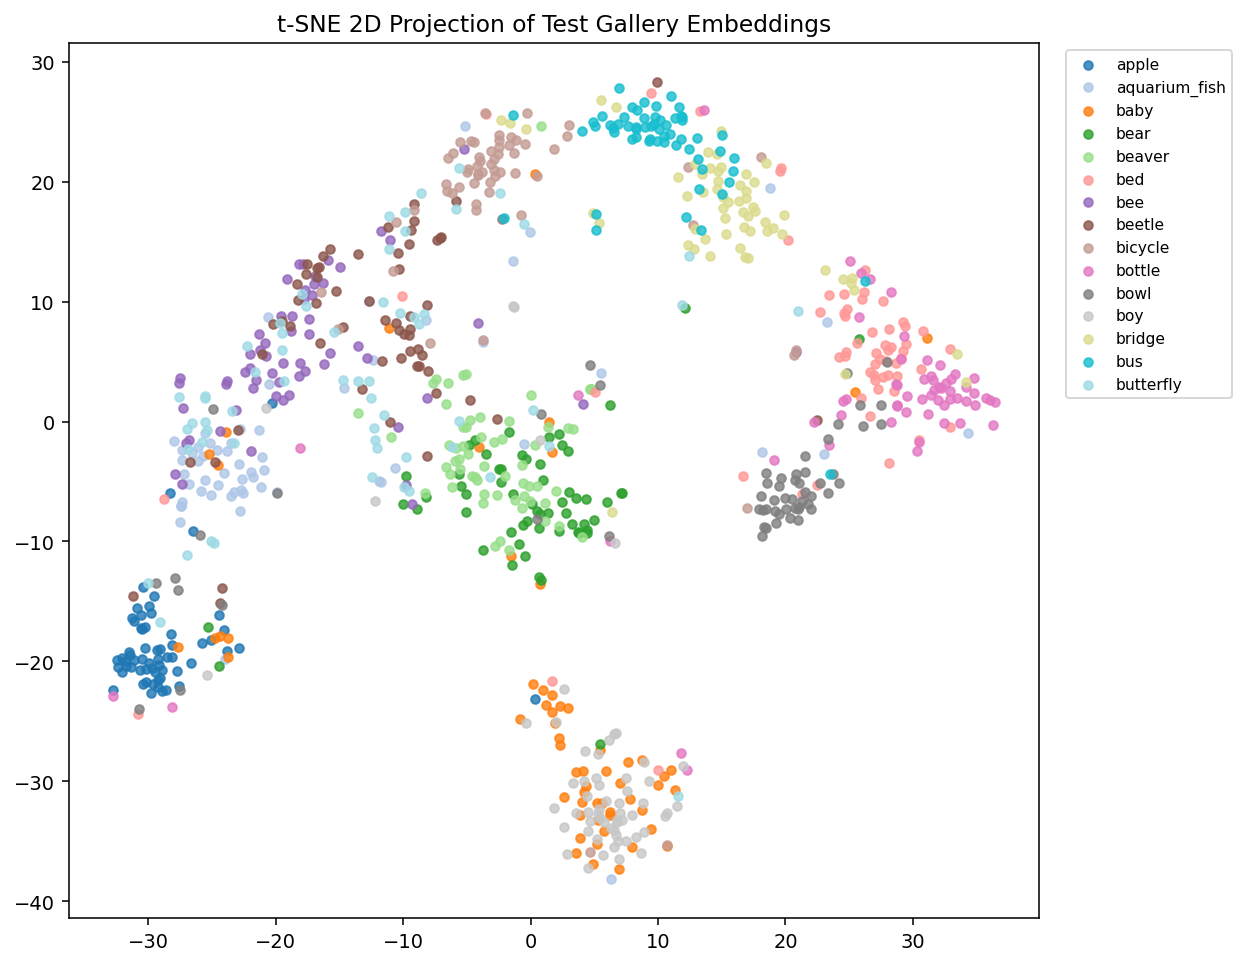

In [3]:
from sklearn.manifold import TSNE


def evaluate_retrieval_metrics(embeddings, labels, ks=(1, 5, 10)):
    dists = l2_distance_matrix(embeddings, embeddings)
    np.fill_diagonal(dists, np.inf)
    order = np.argsort(dists, axis=1)[:, :-1]
    ranked = labels[order]
    matches = (ranked == labels[:, None]).astype(np.float32)

    metrics = {}
    for k in ks:
        hits = np.any(matches[:, :k] > 0.5, axis=1).astype(np.float32)
        metrics[f"Recall@{k}"] = float(np.mean(hits) * 100.0)

    cumsum = np.cumsum(matches, axis=1)
    ranks = np.arange(1, matches.shape[1] + 1, dtype=np.float32)[None, :]
    prec = cumsum / ranks
    n_rel = np.sum(matches, axis=1)
    ap = np.sum(prec * matches, axis=1) / np.maximum(n_rel, 1.0)
    metrics["mAP"] = float(np.mean(ap) * 100.0)
    return metrics


base_metrics = evaluate_retrieval_metrics(test_embeddings, test_labels)
print("Full Test Split Results (lr=1e-3, batch_size=128, margin=0.3, dim=128, hard mining):")
print(
    f"Recall@1: {base_metrics['Recall@1']:.2f}% | "
    f"Recall@5: {base_metrics['Recall@5']:.2f}% | "
    f"Recall@10: {base_metrics['Recall@10']:.2f}% | "
    f"mAP: {base_metrics['mAP']:.2f}%"
)


def plot_tsne(embeddings, labels, class_names, num_classes=15):
    mask = np.isin(labels, np.arange(num_classes))
    sub_e, sub_l = embeddings[mask], labels[mask]
    coords = TSNE(n_components=2, perplexity=30, random_state=42, init="pca", learning_rate="auto").fit_transform(sub_e)
    fig, ax = plt.subplots(figsize=(9, 7), dpi=140)
    cmap = plt.cm.get_cmap("tab20", num_classes)
    for i in range(num_classes):
        idx = sub_l == i
        ax.scatter(coords[idx, 0], coords[idx, 1], s=20, alpha=0.8, color=cmap(i), label=class_names[i])
    ax.set_title("t-SNE 2D Projection of Test Gallery Embeddings")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.savefig("./artifacts/tsne_test_gallery.png", bbox_inches="tight")
    plt.show()


plot_tsne(test_embeddings, test_labels, class_names)

RUN_ALL_ABLATION_MODELS = False
ablation_epochs = 15

if RUN_ALL_ABLATION_MODELS:
    ablation_configs = [
        ("Margin", "0.1", 128, 0.1, "hard"),
        ("Margin", "0.3", 128, 0.3, "hard"),
        ("Margin", "0.5", 128, 0.5, "hard"),
        ("Embedding dim", "64", 64, 0.3, "hard"),
        ("Embedding dim", "128", 128, 0.3, "hard"),
        ("Embedding dim", "256", 256, 0.3, "hard"),
        ("Mining strategy", "random", 128, 0.3, "random"),
        ("Mining strategy", "hard", 128, 0.3, "hard"),
    ]
    print("\n| Ablation | Variant | lr | Batch Size | Val Acc (%) | Recall@1 (%) | Recall@5 (%) | mAP (%) |")
    print("| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |")
    for ab_name, var_name, dim, mar, strat in ablation_configs:
        m_ab, v_acc = train_part1_model(datasets, embedding_dim=dim, margin=mar, mining=strat, epochs=ablation_epochs)
        emb_ab, lbl_ab, _ = extract_test_embeddings(m_ab, datasets["test"])
        met = evaluate_retrieval_metrics(emb_ab, lbl_ab)
        print(f"| {ab_name} | {var_name} | 1e-3 | 128 | {v_acc:.2f} | {met['Recall@1']:.2f} | {met['Recall@5']:.2f} | {met['mAP']:.2f} |")

In [4]:
import base64
import io
from PIL import Image
import gradio as gr


def pil_to_b64(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode("utf-8")


@torch.no_grad()
def query_gallery_ui(pil_img, exclude_self):
    if pil_img is None:
        return "<p>Upload or select a query image below.</p>"
    t0 = time.perf_counter()
    device = next(model.parameters()).device
    img_rgb = pil_img.convert("RGB").resize((32, 32), Image.Resampling.BILINEAR)
    tensor_in = get_transforms(False)(img_rgb).unsqueeze(0).to(device)
    q_emb = model(tensor_in).cpu().numpy()[0]

    ts = time.perf_counter()
    res = retriever.search_l2(q_emb, top_k=5, exclude_self_indices=np.array([0]) if exclude_self else None)
    search_ms = (time.perf_counter() - ts) * 1000.0
    total_ms = (time.perf_counter() - t0) * 1000.0

    cards = []
    for r_i in range(5):
        g_idx = int(res["indices"][0, r_i])
        dist = float(res["distances"][0, r_i])
        cos_s = float(res["cosine_similarities"][0, r_i])
        cls_name = res["class_names"][0][r_i].replace("_", " ").title()
        gal_pil = Image.fromarray(datasets["test"].get_raw_image(g_idx)).resize((260, 260), Image.Resampling.BICUBIC)
        b64 = pil_to_b64(gal_pil)
        cards.append(
            f'<div style="flex:1;min-width:165px;">'
            f'<img src="data:image/png;base64,{b64}" style="width:100%;aspect-ratio:1/1;object-fit:cover;border-radius:18px;" />'
            f'<div style="background:#ffffff;border-radius:16px;border:1px solid #e5e5e1;padding:14px 16px;margin-top:10px;">'
            f'<div style="font-family:monospace;font-size:11px;color:#6c727d;">#{r_i+1:02d} / COSINE {cos_s:.3f}</div>'
            f'<div style="font-size:17px;font-weight:700;color:#20242a;margin:4px 0 6px 0;">{cls_name}</div>'
            f'<div style="font-family:monospace;font-size:11.5px;color:#6c727d;">L2 {dist:.4f}</div>'
            f'</div></div>'
        )

    return (
        f'<div style="background:#efefed;padding:22px;border-radius:20px;font-family:Inter,sans-serif;">'
        f'<h2 style="font-size:26px;font-weight:700;color:#20242a;margin:0 0 6px 0;">Five images, one visual space.</h2>'
        f'<p style="font-size:13px;color:#6c727d;margin:0 0 18px 0;">'
        f'Sorted by ascending L2 distance &middot; search {search_ms:.1f} ms &middot; total {total_ms:.1f} ms &middot; exact self matches excluded: {int(exclude_self)}'
        f'</p><div style="display:flex;gap:16px;flex-wrap:wrap;">{"".join(cards)}</div></div>'
    )


os.makedirs("./artifacts/examples", exist_ok=True)
example_files = []
for idx in [0, 12, 145, 512, 1024]:
    p = f"./artifacts/examples/query_{idx}.png"
    Image.fromarray(datasets["test"].get_raw_image(idx)).resize((160, 160), Image.Resampling.BICUBIC).save(p)
    example_files.append(p)

with gr.Blocks(title="near/near · CIFAR-100") as demo_app:
    gr.HTML(
        '<div style="background:#efefed;padding:18px 24px;border-radius:20px;font-family:Inter,sans-serif;">'
        '<div style="display:flex;justify-content:space-between;align-items:center;border-bottom:1px solid #ddddd8;padding-bottom:12px;margin-bottom:18px;">'
        '<div style="font-size:21px;font-weight:700;color:#20242a;">near/<span style="color:#285ed7;">near</span></div>'
        '<div style="font-family:monospace;font-size:11px;letter-spacing:0.15em;color:#6c727d;">A SMALL STUDY IN VISUAL SIMILARITY &middot; CIFAR-100</div>'
        '<div style="font-family:monospace;font-size:11px;letter-spacing:0.12em;color:#6c727d;">METRIC LEARNING STUDIO &#8599;</div>'
        '</div>'
        '<div style="font-size:28px;font-weight:700;color:#20242a;">Find your nearest neighbors.</div>'
        '</div>'
    )
    with gr.Row():
        with gr.Column(scale=1):
            q_input = gr.Image(type="pil", label="Your query image")
            ex_toggle = gr.Checkbox(label="Exclude exact self match", value=False)
            run_btn = gr.Button("Search Gallery", variant="primary")
            gr.Examples(examples=example_files, inputs=q_input, label="5 Test Split Queries")
        with gr.Column(scale=3):
            out_panel = gr.HTML()

    run_btn.click(fn=query_gallery_ui, inputs=[q_input, ex_toggle], outputs=out_panel)
    q_input.change(fn=query_gallery_ui, inputs=[q_input, ex_toggle], outputs=out_panel)

demo_app.launch(share=True, inline=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://e3ae75db0aaeefbbf2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [7]:
import base64
import io
import os
import time
import numpy as np
from PIL import Image
import torch
import gradio as gr


def pil_to_b64(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode("utf-8")


@torch.no_grad()
def query_gallery_ui(pil_img, exclude_self):
    if pil_img is None:
        pil_img = Image.fromarray(datasets["test"].get_raw_image(0))
    t0 = time.perf_counter()
    device = next(model.parameters()).device
    img_rgb = pil_img.convert("RGB").resize((32, 32), Image.Resampling.BILINEAR)
    tensor_in = get_transforms(False)(img_rgb).unsqueeze(0).to(device)
    q_emb = model(tensor_in).cpu().numpy()[0]

    ts = time.perf_counter()
    res = retriever.search_l2(q_emb, top_k=5, exclude_self_indices=np.array([0]) if exclude_self else None)
    search_ms = (time.perf_counter() - ts) * 1000.0
    total_ms = (time.perf_counter() - t0) * 1000.0

    cards = []
    for r_i in range(5):
        g_idx = int(res["indices"][0, r_i])
        dist = float(res["distances"][0, r_i])
        cos_s = float(res["cosine_similarities"][0, r_i])
        cls_name = res["class_names"][0][r_i].replace("_", " ").title()
        gal_pil = Image.fromarray(datasets["test"].get_raw_image(g_idx)).resize((300, 300), Image.Resampling.BICUBIC)
        b64 = pil_to_b64(gal_pil)
        cards.append(
            f'<div style="display:flex;flex-direction:column;">'
            f'<div style="width:100%;aspect-ratio:1/1;border-radius:18px;overflow:hidden;background:#e5e5e2;box-shadow:0 2px 10px rgba(32,36,42,0.04);">'
            f'<img src="data:image/png;base64,{b64}" style="width:100%;height:100%;object-fit:cover;display:block;" />'
            f'</div>'
            f'<div style="background:#ffffff;border-radius:16px;border:1px solid #e5e5e1;padding:16px 18px;margin-top:12px;box-shadow:0 1px 4px rgba(32,36,42,0.02);">'
            f'<div style="font-family:\'IBM Plex Mono\',monospace;font-size:11px;letter-spacing:0.06em;color:#6c727d;margin-bottom:6px;">&#35;{r_i+1:02d} / COSINE {cos_s:.3f}</div>'
            f'<div style="font-size:17px;font-weight:700;color:#20242a;letter-spacing:-0.015em;margin-bottom:8px;">{cls_name}</div>'
            f'<div style="font-family:\'IBM Plex Mono\',monospace;font-size:11.5px;color:#6c727d;">L2 {dist:.4f}</div>'
            f'</div></div>'
        )

    return (
        f'<div style="padding-top:18px;font-family:Inter,-apple-system,sans-serif;">'
        f'<h2 style="font-size:30px;font-weight:700;letter-spacing:-0.03em;color:#20242a;margin:0 0 8px 0;">Five images, one visual space.</h2>'
        f'<p style="font-size:13.5px;color:#6c727d;margin:0 0 22px 0;">'
        f'Sorted by ascending L2 distance &middot; search {search_ms:.1f} ms &middot; total {total_ms:.1f} ms &middot; exact self matches excluded: {int(exclude_self)}'
        f'</p>'
        f'<div style="display:grid;grid-template-columns:repeat(5,minmax(0,1fr));gap:20px;width:100%;">'
        f'{"".join(cards)}'
        f'</div>'
        f'<div style="border-bottom:1px solid #dcdcd7;margin-top:40px;"></div>'
        f'</div>'
    )


os.makedirs("./artifacts/examples", exist_ok=True)
example_files = []
for idx in [0, 12, 145, 512, 1024]:
    p = f"./artifacts/examples/query_{idx}.png"
    Image.fromarray(datasets["test"].get_raw_image(idx)).resize((180, 180), Image.Resampling.BICUBIC).save(p)
    example_files.append(p)

CUSTOM_CSS = """
@import url('https://fonts.googleapis.com/css2?family=IBM+Plex+Mono:wght@400;500;600&family=Inter:wght@400;500;600;700;800&display=swap');
body, .gradio-container, main, .dark {
    background-color: #efefed !important;
    color: #20242a !important;
    font-family: 'Inter', -apple-system, BlinkMacSystemFont, sans-serif !important;
}
.gradio-container {
    max-width: 1380px !important;
    margin: 0 auto !important;
    padding: 20px 36px 60px 36px !important;
}
.gr-box, .gr-panel, .gr-form, .block {
    background-color: #ffffff !important;
    border-color: #e4e4e0 !important;
    border-radius: 18px !important;
    color: #20242a !important;
    box-shadow: 0 2px 8px rgba(32,36,42,0.02) !important;
}
button.primary {
    background: #285ed7 !important;
    color: #ffffff !important;
    border: none !important;
    border-radius: 9999px !important;
    font-weight: 600 !important;
}
label, span, p {
    color: #20242a !important;
}
"""

HEADER_AND_HERO_HTML = """
<div style="font-family:'Inter',sans-serif;color:#20242a;">
  <div style="display:flex;align-items:center;justify-content:space-between;padding:8px 0 18px 0;border-bottom:1px solid #ddddd8;margin-bottom:28px;">
    <div style="font-size:21px;font-weight:700;letter-spacing:-0.035em;color:#20242a;">near/<span style="color:#285ed7;">near</span></div>
    <div style="font-family:'IBM Plex Mono',monospace;font-size:11px;letter-spacing:0.17em;color:#6c727d;text-transform:uppercase;">A SMALL STUDY IN VISUAL SIMILARITY &middot; CIFAR-100</div>
    <div style="font-family:'IBM Plex Mono',monospace;font-size:11px;letter-spacing:0.14em;color:#6c727d;text-transform:uppercase;">METRIC LEARNING STUDIO &#8599;</div>
  </div>

  <div style="background:linear-gradient(180deg,#e5e5e3 0%,#e7e7e5 100%);border-radius:22px;min-height:390px;padding:34px 40px;position:relative;overflow:hidden;display:flex;flex-direction:column;justify-content:space-between;margin-bottom:44px;border:1px solid rgba(255,255,255,0.6);">
    <div style="display:flex;align-items:center;justify-content:space-between;position:relative;min-height:270px;">
      <div style="z-index:3;color:#285ed7;font-size:13px;line-height:1.45;">[ From pixels<br/>to neighborhoods ]</div>
      <div style="position:absolute;inset:0;display:flex;flex-direction:column;align-items:center;justify-content:center;font-size:clamp(74px,11vw,148px);font-weight:700;line-height:0.86;letter-spacing:-0.045em;color:#f9f9f8;user-select:none;pointer-events:none;">
        <div>LOOK</div>
        <div>&amp; FIND</div>
      </div>
      <div style="width:214px;height:214px;border-radius:9999px;margin:0 auto;z-index:2;background:radial-gradient(circle at 36% 34%,rgba(255,255,255,0.98) 0%,rgba(255,255,255,0.65) 26%,rgba(255,255,255,0) 62%),conic-gradient(from 205deg at 50% 50%,#d4dff2 0deg,#edd0e5 65deg,#d1dbf2 135deg,#eaf3fa 205deg,#f3dfcf 285deg,#d4dff2 360deg);border:1.5px solid rgba(255,255,255,0.92);box-shadow:0 20px 44px rgba(40,52,74,0.11),inset 0 0 22px rgba(255,255,255,0.85);position:relative;">
        <div style="position:absolute;inset:7px;border-radius:9999px;border:1px solid rgba(255,255,255,0.78);"></div>
      </div>
      <div style="z-index:3;color:#285ed7;font-size:13px;line-height:1.45;text-align:right;">Find images that share a visual neighborhood.</div>
    </div>
    <div style="display:flex;justify-content:center;z-index:3;padding-top:8px;">
      <div style="background:#ffffff;color:#285ed7;border:1px solid #dfdfe2;border-radius:9999px;padding:9px 20px;font-size:12.5px;font-weight:500;box-shadow:0 4px 14px rgba(32,36,42,0.045);">Upload a query to explore the gallery &#8599;</div>
    </div>
  </div>

  <div style="font-family:'IBM Plex Mono',monospace;font-size:11px;letter-spacing:0.15em;color:#6c727d;text-transform:uppercase;margin-bottom:8px;">01 / SEARCH WORKSPACE</div>
  <div style="display:flex;align-items:center;justify-content:space-between;margin-bottom:22px;">
    <h1 style="font-size:32px;font-weight:700;letter-spacing:-0.03em;color:#20242a;margin:0;">Find your nearest neighbors.</h1>
    <div style="background:#ffffff;border:1px solid #e1e1dd;border-radius:9999px;padding:6px 15px;font-family:'IBM Plex Mono',monospace;font-size:11px;letter-spacing:0.1em;color:#454b54;display:inline-flex;align-items:center;gap:8px;">
      <span style="width:8px;height:8px;border-radius:50%;background:#2e9b63;display:inline-block;"></span>MODEL + INDEX READY
    </div>
  </div>

  <div style="display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:20px;margin-bottom:20px;">
    <div style="background:#ffffff;border-radius:18px;border:1px solid #e4e4e0;padding:22px 26px;box-shadow:0 2px 8px rgba(32,36,42,0.02);">
      <div style="font-size:15.5px;font-weight:700;color:#20242a;margin-bottom:6px;">Your query image</div>
      <div style="font-size:14px;color:#68707c;">Upload a picture to search the CIFAR-100 gallery.</div>
    </div>
    <div style="background:#ffffff;border-radius:18px;border:1px solid #e4e4e0;padding:22px 26px;box-shadow:0 2px 8px rgba(32,36,42,0.02);">
      <div style="font-size:15.5px;font-weight:700;color:#20242a;margin-bottom:6px;">How the search works</div>
      <div style="font-size:14px;color:#68707c;">ResNet-18 &rarr; normalized 128-D embedding &rarr; exact NumPy L2 search. Five neighbors appear with class labels, distances, and cosine similarity.</div>
    </div>
  </div>
  <div style="font-size:14px;font-weight:600;color:#20242a;margin-bottom:8px;">Query source</div>
</div>
"""

FORCE_LIGHT_JS = "() => { document.body.classList.remove('dark'); document.documentElement.style.colorScheme = 'light'; }"

with gr.Blocks(title="near/near · CIFAR-100", css=CUSTOM_CSS, js=FORCE_LIGHT_JS) as demo_app:
    gr.HTML(HEADER_AND_HERO_HTML)
    with gr.Row():
        with gr.Column(scale=1):
            q_input = gr.Image(type="pil", value=example_files[1], label="Your query image", height=200)
        with gr.Column(scale=2):
            ex_toggle = gr.Checkbox(label="Exclude exact self match", value=False)
            run_btn = gr.Button("Upload a query to explore the gallery ↗", variant="primary")
            gr.Examples(examples=example_files, inputs=q_input, label="CIFAR-100 Test Gallery Samples (Click any image)")

    out_panel = gr.HTML(value=query_gallery_ui(Image.open(example_files[1]), False))

    run_btn.click(fn=query_gallery_ui, inputs=[q_input, ex_toggle], outputs=out_panel)
    q_input.change(fn=query_gallery_ui, inputs=[q_input, ex_toggle], outputs=out_panel)
    ex_toggle.change(fn=query_gallery_ui, inputs=[q_input, ex_toggle], outputs=out_panel)

demo_app.launch(share=True, inline=True)

/tmp/ipykernel_49/835748068.py:153: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css, js. Please pass these parameters to launch() instead.
  with gr.Blocks(title="near/near · CIFAR-100", css=CUSTOM_CSS, js=FORCE_LIGHT_JS) as demo_app:


* Running on local URL:  http://127.0.0.1:7863
* Running on public URL: https://c17eb216e1a3430d55.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
